# Explore > COLUMN

> Market Values of Good and Services in a Country

# Imports

In [1]:
import matplotlib.pyplot as plt
from scipy import stats

from Q1_OLD_OLD.consts import *

from utils.read_csv_to_df import read_csv_to_df
from utils.plot_hist_with_normal_dist_overlay import plot_hist_with_normal_dist_overlay
from utils.rule_of_thumb__skewness import rule_of_thumb__skewness
from utils.rule_of_thumb__kurtosis import rule_of_thumb__kurtosis
from utils.plot_correlation_to_target import plot_correlation_to_target
from utils.preprocessing.transform import *

# Defaults

In [2]:
COLUMN = columns['LGDP']

# Fetch Data

In [3]:
train_df = read_csv_to_df(path=TRAIN_PATH)

---

# Summary

In [4]:
train_df[COLUMN].info()

LogGdpPerCapita_stats = train_df[[COLUMN]].describe().T

q1, q3 = train_df[COLUMN].quantile(0.25), train_df[COLUMN].quantile(0.75)
iqr = q3 - q1
LogGdpPerCapita_stats['IQR outliers'] = (
	(train_df[COLUMN] < q1 - 1.5 * iqr) | (train_df[COLUMN] > q3 + 1.5 * iqr)
).sum()

LogGdpPerCapita_stats

<class 'pandas.core.series.Series'>
RangeIndex: 1559 entries, 0 to 1558
Series name: Log GDP per capita
Non-Null Count  Dtype  
--------------  -----  
1533 non-null   float64
dtypes: float64(1)
memory usage: 12.3 KB


,count,mean,std,min,25%,50%,75%,max,IQR outliers
Log GDP per capita,1533.0,9.362995,1.16024,6.635,8.46,9.456,10.332,11.648,0


In [5]:
missing_values_LogGdpPerCapita = train_df[COLUMN].isna().sum()
count_LogGdpPerCapita = train_df[COLUMN].count()

print(f"{missing_values_LogGdpPerCapita} missing values out of {count_LogGdpPerCapita} -> {round(missing_values_LogGdpPerCapita / count_LogGdpPerCapita, 2)}%")

26 missing values out of 1533 -> 0.02%


# Plots

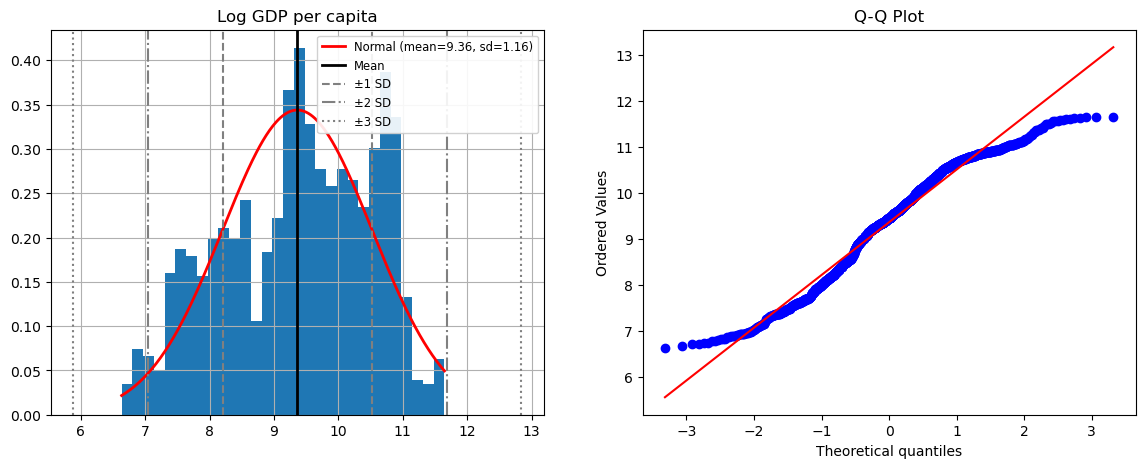

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

plot_hist_with_normal_dist_overlay(
    series=train_df[COLUMN],
    bins=HIST_BINS,
    ax=ax1
)

stats.probplot(
	train_df[COLUMN].dropna(),
	dist="norm",
	plot=ax2)
ax2.set_title("Q-Q Plot")

plt.show()

# Correlation to Target

<Axes: title={'center': 'Life Ladder vs Log GDP per capita'}, xlabel='Log GDP per capita', ylabel='Life Ladder'>

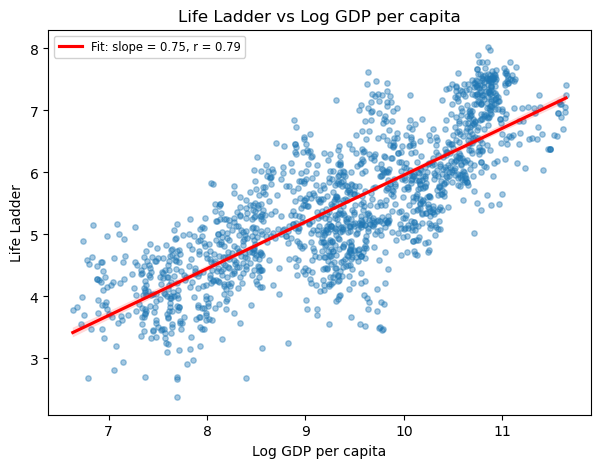

In [7]:
plot_correlation_to_target(
	df=train_df,
	feature="Log GDP per capita",
	target=TARGET,
)

In [8]:
correlation_to_target_LogGdpPerCapita = train_df[TARGET].corr(train_df["Log GDP per capita"])
print(f"Correlation: {correlation_to_target_LogGdpPerCapita:.3f}")

Correlation: 0.787


# Skew & Kurtosis

In [9]:
LogGdpPerCapitaSkew = train_df[COLUMN].skew()
LogGdpPerCapitaSkew_RuleOfThumb = rule_of_thumb__skewness(series=train_df["Log GDP per capita"])
LogGdpPerCapitaKurtosis = train_df[COLUMN].kurt()
LogGdpPerCapitaKurtosis_RuleOfThumb = rule_of_thumb__kurtosis(series=train_df[COLUMN])

print(f'Log GDP per Capita Skew: {LogGdpPerCapitaSkew:.3f} -> {LogGdpPerCapitaSkew_RuleOfThumb}')
print(f'Log GDP per Capita Kurtosis: {LogGdpPerCapitaKurtosis:.3f} -> {LogGdpPerCapitaKurtosis_RuleOfThumb}')

Log GDP per Capita Skew: -0.292 -> Roughly symmetric
Log GDP per Capita Kurtosis: -0.858 -> Mesokurtic (near-normal tails)


In [10]:
LogGdpPerCapitaTransformed = compare_all_transforms(series=train_df["Log GDP per capita"])
LogGdpPerCapitaTransformed

,skew_before,skew_after,skew_diff,kurt_before,kurt_after,kurt_diff,skew_rule_after
transform,,,,,,,
rank,-0.292395,-0.000223,2.921718e-01,-0.857795,-1.200078,-3.422829e-01,Roughly symmetric
quantile,-0.292395,0.002588,2.949835e-01,-0.857795,0.644244,1.502039e+00,Roughly symmetric
yeo_johnson,-0.292395,-0.082694,2.097011e-01,-0.857795,-0.951708,-9.391246e-02,Roughly symmetric
box_cox,-0.292395,-0.086491,2.059046e-01,-0.857795,-0.952301,-9.450566e-02,Roughly symmetric
square,-0.292395,-0.094038,1.983576e-01,-0.857795,-0.950772,-9.297707e-02,Roughly symmetric
cube,-0.292395,0.097148,3.895429e-01,-0.857795,-0.943614,-8.581866e-02,Roughly symmetric
clip,-0.292395,-0.291819,5.761700e-04,-0.857795,-0.889271,-3.147567e-02,Roughly symmetric
shift,-0.292395,-0.292395,-2.275957e-15,-0.857795,-0.857795,8.881784e-16,Roughly symmetric
reflect_log,-0.292395,-0.348138,-5.574271e-02,-0.857795,-0.563043,2.947524e-01,Roughly symmetric


---

### Notes / Observations
#### General
- 26 missing values (1.7% of rows) and no IQR outliers.
- Already on a log scale, ranging from 6.6 to 11.6 (mean 9.36, median 9.46).
- The histogram has several humps (around 7.5, 9.3 and 10.8) and a dip near 8.8, so countries fall into rough income groups rather than one smooth bell.
- The QQ plot has an S shape with flat ends: light tails (kurtosis -0.86) and no extreme outliers.
- Strongest link to happiness of any feature (r = 0.79). The scatter follows a clear, fairly tight straight line: richer countries are happier.
- Very closely tied to Healthy life expectancy (r = 0.85) and Social support (r = 0.70).
- **Takeaway:** best single predictor, and the log scale already makes the relationship look linear.

#### Transforming
- Not needed: it is already log transformed and roughly symmetric (skew -0.29).
- yeo_johnson (-0.08) and square (-0.09) only nudge the skew, and log or sqrt push it the wrong way (-0.50, -0.39).
- Another transform would risk bending the straight line it already has with the target.

#### Scaling
- Needs scaling: its range (6.6 to 11.6, std 1.16) is far from the 0 to 1 features.
- StandardScaler fits well: no outliers and near symmetric, so the mean and std are representative.

#### Imputing
- All 26 rows missing GDP are also missing Generosity, so those rows lose two features at once.
- The multi hump shape means a single median (9.46) does not represent any income group well.
- Better to impute from related features with IterativeImputer or KNNImputer: Healthy life expectancy (r = 0.85) and Social support (r = 0.70) are strong sources.
- Median SimpleImputer is an acceptable fallback given only 1.7% missing.